Micrograd

Andrej Karpathy 的教學影片
https://youtu.be/VMj-3S1tku0?si=XPFS2taHYZPXrT-s

In [ ]:
import math
# 初始化神經網路權重
import random  
import matplotlib.pyplot as plt


定義核心 Value 類別實現自動微分

In [2]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data}, grad={self.grad})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += out.grad * 1.0
            other.grad += out.grad * 1.0
        out._backward = _backward

        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data
        out._backward = _backward

        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers"
        out = Value(self.data ** other, (self,), f'**{other}')

        def _backward():
            self.grad += out.grad * (other * self.data ** (other - 1))
        out._backward = _backward

        return out

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    # self / other
    def __truediv__(self, other):  
        return self * other ** -1

    # other * self 
    def __rmul__(self, other):
        return self * other

    def __radd__(self, other):
        return self + other

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad += out.grad * out.data
        out._backward = _backward

        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, (self,), 'tanh')

        def _backward():
            self.grad += out.grad * (1 - t**2)
        out._backward = _backward

        return out

    def backward(self):
        # 建立從起點到最終輸出的拓撲排序
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        # 從輸出開始：grad = 1.0
        self.grad = 1.0

        # 反轉拓樸順序才能 backward
        for v in reversed(topo):
            v._backward()

視覺化計算圖

用 draw_dot() 畫出計算圖：每個節點顯示 `label`、`data`、`grad`，連線標示運算。

In [3]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid, label=f'{{ {n.label} | data {n.data:.4f} | grad {n.grad:.4f} }}', shape='record')
        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

手動測試 Value 與反向傳播

L.data = -8.0
a.grad = 6.0
b.grad = -4.0
c.grad = -2.0
f.grad = 4.0


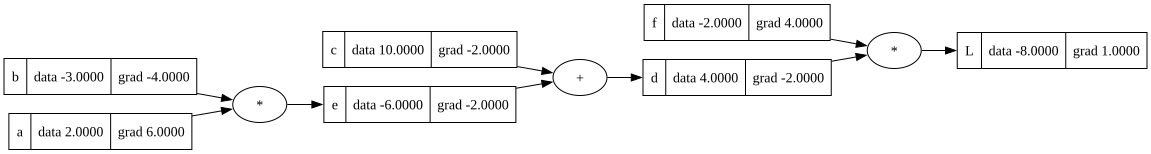

In [4]:
# 示範：簡單表達式 a*b + c
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a * b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d * f; L.label = 'L'

L.backward()
print(f"L.data = {L.data}")
print(f"a.grad = {a.grad}")
print(f"b.grad = {b.grad}")
print(f"c.grad = {c.grad}")
print(f"f.grad = {f.grad}")

draw_dot(L)

o.data = 0.7071067811865476
x1.grad = -1.4999999999999996
x2.grad = 0.4999999999999999
w1.grad = 0.9999999999999998
w2.grad = 0.0
b.grad  = 0.4999999999999999


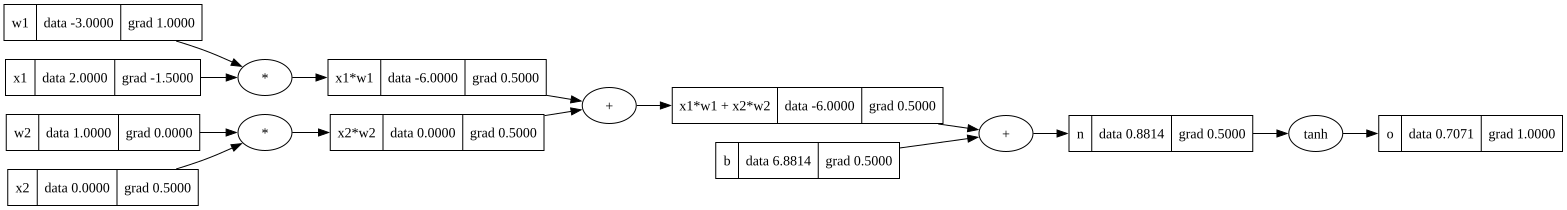

In [5]:
# 示範：神經網路中的神經元
# 輸入 x1, x2 → 權重 w1, w2 → sum → tanh 激活
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')

x1w1 = x1 * w1; x1w1.label = 'x1*w1'
x2w2 = x2 * w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

o.backward()
print(f"o.data = {o.data}")
print(f"x1.grad = {x1.grad}")
print(f"x2.grad = {x2.grad}")
print(f"w1.grad = {w1.grad}")
print(f"w2.grad = {w2.grad}")
print(f"b.grad  = {b.grad}")

draw_dot(o)

《神經網路模組》

建構 Neuron → Layer → MLP（多層感知器）

In [6]:
class Neuron:
    def __init__(self, nin):
        # nin(number of inputs): 接收的輸入特徵數量，每個輸入配一個權重 + bias
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        # 用 zip 準備 w * x + b 運算(self.w、x配對)，然後 tanh 激活，輸出壓制在 -1 到 1 之間並返回
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()    
        return out

     # 返回該神經元所有需要被優化/訓練的參數列表
    def parameters(self):
        return self.w + [self.b]

     # 定義物件的字串顯示方式
    def __repr__(self):
        return f"Neuron({len(self.w)})"
 

class Layer:
    def __init__(self, nin, nout):
        # nin：輸入維度（每個神經元接收多少特徵）; nout：輸出維度（這一層包含多少個神經元)，建立出來的神經元一個裝進列表
        self.neurons = [Neuron(nin) for _ in range(nout)]

    # 如果輸出維度只有 1，直接返回單一純量值，否則返回列表。
    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    # 收集並展平這一層中所有神經元的參數，方便審查更新梯度
    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]

    def __repr__(self):
        return f"Layer({[str(n) for n in self.neurons]})"


class MLP:
    def __init__(self, nin, nouts):
        # 建立所有神經層，nouts 是一個列表，例如 [4, 4, 1] 表示兩個隱藏層與一個輸出層
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    # 資料 x 進來後，x 計算出結果，覆蓋變成新的 x，直到最後一層算完，傳回最終結果。
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    # 把每層展平，讓所有神經元裡面的權重和偏差全部展平成一大排。
    def parameters(self):
        return [p for l in self.layers for p in l.parameters()]

    # 方便在 Python 裡面印出這個物件時，能清楚看到這張網路裡面包含了哪些 Layer，方便除錯與檢視。
    def __repr__(self):
        return f"MLP({[str(l) for l in self.layers]})"

測試 MLP 的前向傳播

In [7]:
# 2 個輸入 → 隱藏層 16 個神經元 → 輸出層 1 個神經元
model = MLP(2, [16, 1])
print(model)
print(f"參數數量: {len(model.parameters())}")

# 前向傳播
xs = [Value(2.0), Value(3.0)]
pred = model(xs)
print(f"預測值: {pred.data}")

MLP(["Layer(['Neuron(2)', 'Neuron(2)', 'Neuron(2)', 'Neuron(2)', 'Neuron(2)', 'Neuron(2)', 'Neuron(2)', 'Neuron(2)', 'Neuron(2)', 'Neuron(2)', 'Neuron(2)', 'Neuron(2)', 'Neuron(2)', 'Neuron(2)', 'Neuron(2)', 'Neuron(2)'])", "Layer(['Neuron(16)'])"])
參數數量: 65
預測值: 0.905825957435526


《二元分類訓練》  

使用 micrograd 訓練一個簡單的二元分類器

In [18]:
# 訓練資料：兩組點
xs = [
    [2.0,  3.0,  -1.0],
    [3.0, -1.0,  0.5],
    [0.5,  1.0,  1.0],
    [1.0,  1.0,  -1.0],
    ]

# desire targets
ys = [1.0, -1.0, -1.0, 1.0]

# 建立 MLP
model = MLP(3, [16, 16, 1])
print(f"參數數量: {len(model.parameters())}")

In [16]:
# 訓練循環
# 建立一個空列表，用來紀錄每次迭代後的 loss 數值
loss_history = []

for k in range(100):
    # 將所有輸入樣本 xs 依序傳入 model 中，得到當前模型對所有樣本的預測結果 ypred。
    ypred = [model(x) for x in xs]

    # 損失函數：(y - ypred)^2（MSE）
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))

    # 反向傳播（歸零梯度 → backward）
    # 自動計算出 loss 對每一個參數 p 的偏微分（梯度），並儲存在 p.grad 中。
    for p in model.parameters():
        p.grad = 0.0
    loss.backward()

    # 梯度下降更新參數， data = data - learning_rate * grad
    # 梯度是正/負的，代表增加該參數會讓 loss 變大/小，所以要減去/加上它。
    for p in model.parameters():
        p.data += -0.1 * p.grad

    loss_history.append(loss.data)

    if k % 20 == 0:
        print(f"step {k}: loss = {loss.data:.4f}")

print(f"final loss = {loss.data:.4f}")

step 0: loss = 3.9998
step 20: loss = 3.9998
step 40: loss = 3.9998
step 60: loss = 3.9997
step 80: loss = 3.9997
final loss = 3.9997


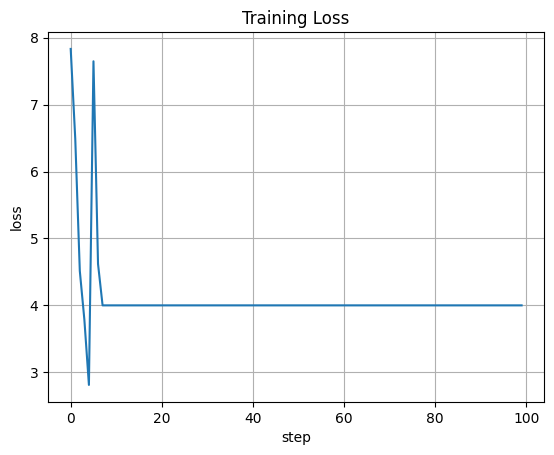

In [10]:
# 繪製損失曲線
plt.plot(loss_history)
plt.xlabel('step')
plt.ylabel('loss')
plt.title('Training Loss')
plt.grid(True)
plt.show()

In [11]:
# 查看訓練後的預測
print("訓練結果：")
for x, ygt in zip(xs, ys):
    pred = model(x)
    print(f"輸入 {x} → 預測 {pred.data:.3f} (目標 {ygt})")

訓練結果：
輸入 [2.0, 3.0, -1.0] → 預測 1.000 (目標 1.0)
輸入 [3.0, -1.0, 0.5] → 預測 -0.990 (目標 -1.0)
輸入 [0.5, 1.0, 1.0] → 預測 1.000 (目標 -1.0)
輸入 [1.0, 1.0, -1.0] → 預測 1.000 (目標 1.0)
